# Data Cleaning and Validation

This notebook contains the completed data-cleaning checks and descriptive EDA. Statistical testing, feature engineering, and modeling are not included.

In [1]:
from pathlib import Path
import sys

import pandas as pd

project_root = Path.cwd()
if not (project_root / "python" / "data_cleaning.py").is_file():
    project_root = Path.cwd().parent
sys.path.insert(0, str(project_root / "python"))

from data_cleaning import (
    build_quality_report,
    check_binary_columns,
    check_categorical_values,
    check_duplicates,
    check_eligibility_consistency,
    check_missing_values,
    clean_data,
    load_data,
    save_clean_data,
    save_quality_report,
)

## Load the source data

In [2]:
data = load_data(project_root / "data" / "ab_test_dataset.csv")
print("Dataset shape:", data.shape)

Dataset shape: (11462, 16)


In [3]:
data.head()

,user_id,variant,assigned_at,signup_ts,data_end_date,onboarding_completed,trial_eligible,trial_started,paid_eligible,paid_conversion,d1_eligible,d1_retained,d7_eligible,d7_retained,d30_eligible,d30_retained
0,usr_011313,control,2025-04-20 16:00:47+00:00,2025-04-20 16:00:09+00:00,2025-08-15,1,1,1,1,1,1,0,1,0,1,0
1,usr_011325,control,2025-04-15 09:59:27+00:00,2025-04-15 09:59:05+00:00,2025-08-15,1,1,0,1,0,1,0,1,1,1,1
2,usr_011326,control,2025-04-30 06:03:24+00:00,2025-04-30 06:03:01+00:00,2025-08-15,1,1,1,1,1,1,1,1,0,1,1
3,usr_011329,control,2025-04-28 18:11:17+00:00,2025-04-28 18:10:49+00:00,2025-08-15,1,1,0,1,0,1,1,1,0,1,0
4,usr_011336,control,2025-04-30 14:38:41+00:00,2025-04-30 14:38:16+00:00,2025-08-15,1,1,1,1,1,1,1,1,1,1,1


In [4]:
data.dtypes

user_id                   str
variant                   str
assigned_at               str
signup_ts                 str
data_end_date             str
onboarding_completed    int64
trial_eligible          int64
trial_started           int64
paid_eligible           int64
paid_conversion         int64
d1_eligible             int64
d1_retained             int64
d7_eligible             int64
d7_retained             int64
d30_eligible            int64
d30_retained            int64
dtype: object

## Check missing values and duplicates

In [5]:
missing_summary = check_missing_values(data)
missing_summary

,Column,Missing Count,Missing %
0,user_id,0,0.0
1,variant,0,0.0
2,assigned_at,0,0.0
3,signup_ts,0,0.0
4,data_end_date,0,0.0
5,onboarding_completed,0,0.0
6,trial_eligible,0,0.0
7,trial_started,0,0.0
8,paid_eligible,0,0.0
9,paid_conversion,0,0.0


In [6]:
duplicate_summary = check_duplicates(data)
duplicate_summary

{'duplicate_rows': 0, 'duplicate_users': 0, 'duplicate_user_rows': 0}

## Validate experiment groups and binary fields

In [7]:
variant_summary = check_categorical_values(data)
variant_summary

,Variant,User Count,Assignment Share (%),Valid
0,control,5677,49.528878,True
1,treatment,5785,50.471122,True


In [8]:
binary_summary = check_binary_columns(data)
binary_summary

,Column,Observed Values,Invalid Value Count
0,onboarding_completed,"0, 1",0
1,trial_eligible,1,0
2,trial_started,"0, 1",0
3,paid_eligible,1,0
4,paid_conversion,"0, 1",0
5,d1_eligible,1,0
6,d1_retained,"0, 1",0
7,d7_eligible,1,0
8,d7_retained,"0, 1",0
9,d30_eligible,1,0


In [9]:
eligibility_summary, inconsistent_record_count = check_eligibility_consistency(data)
eligibility_summary


,Eligibility Column,Outcome Column,Inconsistent Rows
0,trial_eligible,trial_started,0
1,paid_eligible,paid_conversion,0
2,d1_eligible,d1_retained,0
3,d7_eligible,d7_retained,0
4,d30_eligible,d30_retained,0


## Clean and save validated records

The script preserves the raw CSV. Invalid records are counted and excluded by explicit validation rules; duplicate users are never automatically removed.

In [10]:
cleaned_data = clean_data(data)
quality_report = build_quality_report(data, cleaned_data)
clean_data_path = save_clean_data(cleaned_data)
quality_report_path = save_quality_report(quality_report)
print("Cleaned dataset:", clean_data_path)
print("Quality report:", quality_report_path)
quality_report

Cleaned dataset: C:\Users\ANUSHKA JAIN\Downloads\mobile-subscription-product-analytics-main\mobile-subscription-product-analytics-main\outputs\cleaned_data\cleaned_ab_test_dataset.csv
Quality report: C:\Users\ANUSHKA JAIN\Downloads\mobile-subscription-product-analytics-main\mobile-subscription-product-analytics-main\outputs\cleaned_data\data_quality_report.csv


,Metric,Value
0,Original Rows,11462.0000
1,Cleaned Rows,11462.0000
2,Rows Removed,0.0000
3,Unique Users (Cleaned),11462.0000
4,Duplicate Rows,0.0000
5,Duplicate Users,0.0000
6,Duplicate User Rows,0.0000
7,Missing Cells,0.0000
8,Invalid Variants,0.0000
9,Missing Expected Variants,0.0000


In [11]:
cleaned_data.head()

,user_id,variant,assigned_at,signup_ts,data_end_date,onboarding_completed,trial_eligible,trial_started,paid_eligible,paid_conversion,d1_eligible,d1_retained,d7_eligible,d7_retained,d30_eligible,d30_retained
0,usr_011313,control,2025-04-20 16:00:47+00:00,2025-04-20 16:00:09+00:00,2025-08-15,1,1,1,1,1,1,0,1,0,1,0
1,usr_011325,control,2025-04-15 09:59:27+00:00,2025-04-15 09:59:05+00:00,2025-08-15,1,1,0,1,0,1,0,1,1,1,1
2,usr_011326,control,2025-04-30 06:03:24+00:00,2025-04-30 06:03:01+00:00,2025-08-15,1,1,1,1,1,1,1,1,0,1,1
3,usr_011329,control,2025-04-28 18:11:17+00:00,2025-04-28 18:10:49+00:00,2025-08-15,1,1,0,1,0,1,1,1,0,1,0
4,usr_011336,control,2025-04-30 14:38:41+00:00,2025-04-30 14:38:16+00:00,2025-08-15,1,1,1,1,1,1,1,1,1,1,1


## Section B — Exploratory Data Analysis

The analysis below uses the cleaned output. It describes actual group counts, ordered funnel progression, eligibility-based retention, group comparisons, and the observed assignment-date range. It does not perform statistical tests.

In [12]:
from eda_analysis import load_cleaned_data, run_eda

eda_data = load_cleaned_data()
print("Cleaned dataset shape:", eda_data.shape)
eda_results = run_eda(eda_data)

Cleaned dataset shape: (11462, 16)


,Metric,Value
0,Total Users,11462.000000
1,Total Columns,16.000000
2,Control Users,5677.000000
3,Treatment Users,5785.000000
4,Control Percentage,49.528878
5,Treatment Percentage,50.471122
6,Onboarding Users,6291.000000
7,Trial Users,1878.000000
8,Paid Users,1123.000000
9,D1 Retained Users,4669.000000


,Variant,Users,Percentage
0,control,5677,49.528878
1,treatment,5785,50.471122


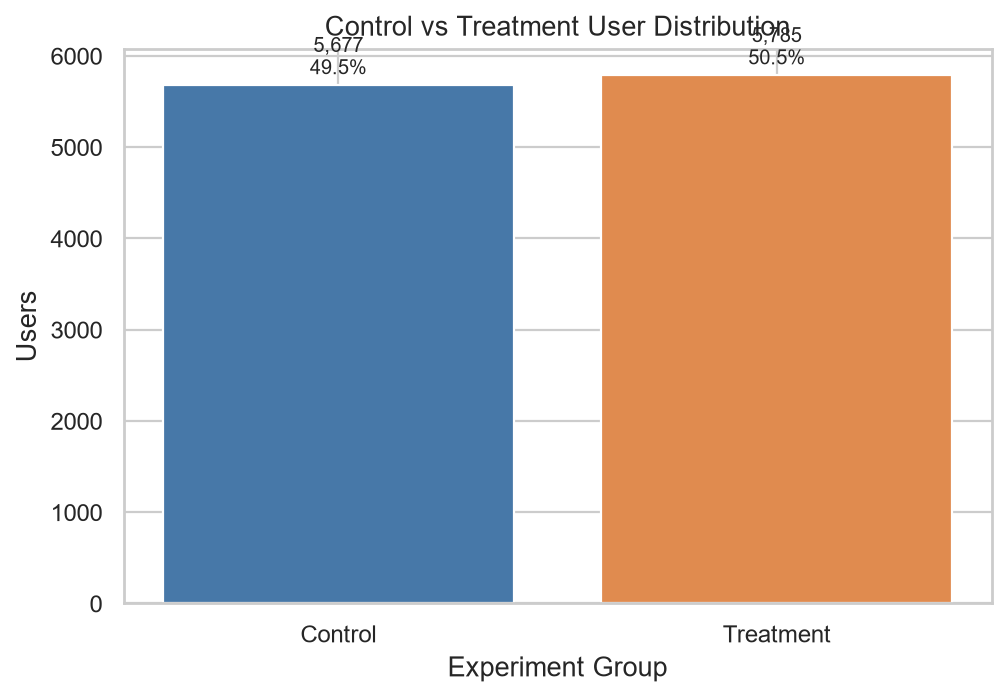

In [13]:
from IPython.display import Image, display

display(eda_results["summary"])
display(eda_results["groups"])
display(Image(filename=str(project_root / "outputs" / "eda" / "experiment_group_distribution.png")))

,Stage,Users,Conversion_Rate,Dropoff_Users,Dropoff_Percentage
0,Assigned,11462,100.000000,5171,45.114291
1,Onboarding Completed,6291,54.885709,4417,70.211413
2,Trial Started,1874,29.788587,781,41.675560
3,Paid Conversion,1093,58.324440,0,0.000000


,Variant,Assigned Users,Onboarding,Trial,Paid,Onboarding Rate,Trial Rate,Paid Rate
0,control,5677,3020,886,565,53.197111,29.337748,63.769752
1,treatment,5785,3271,988,528,56.542783,30.204830,53.441296


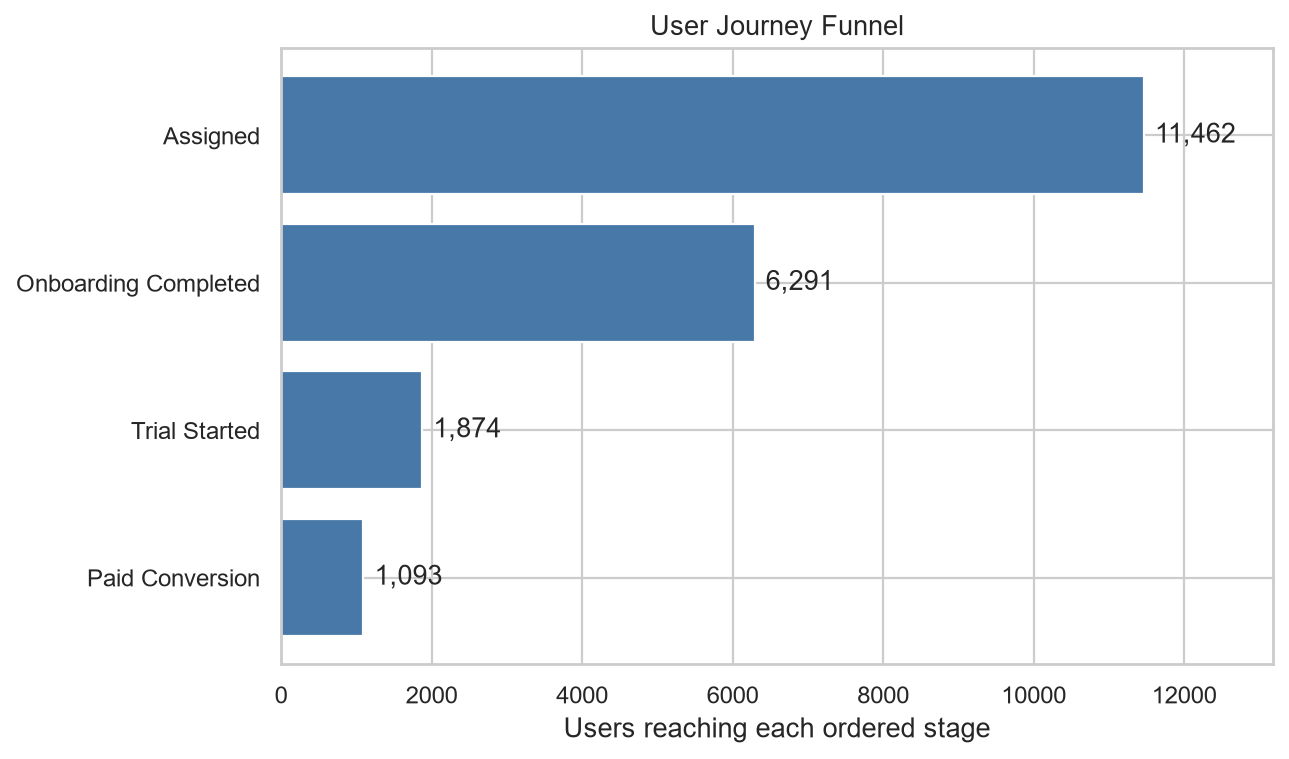

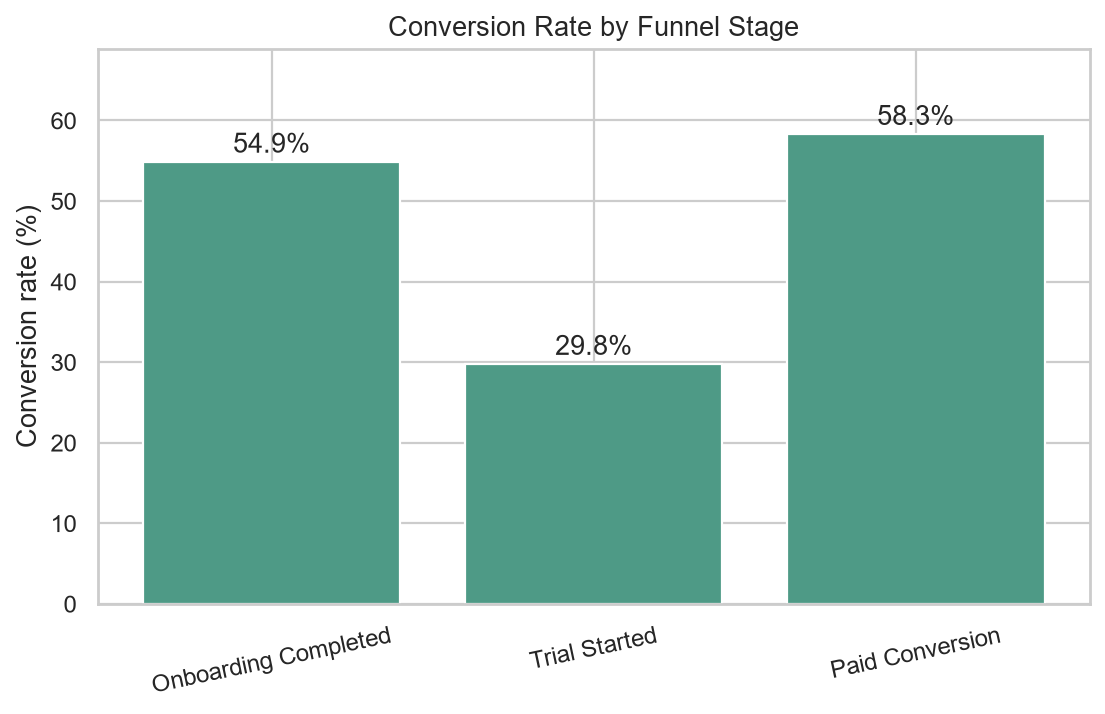

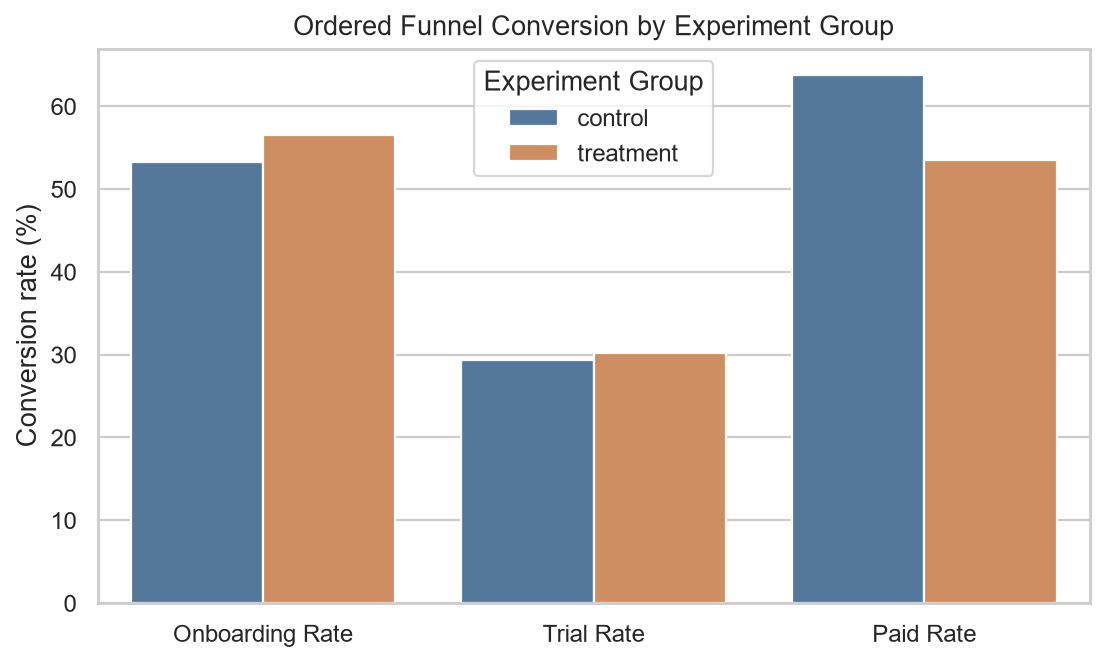

In [14]:
display(eda_results["funnel"])
display(eda_results["funnel_by_variant"])
display(Image(filename=str(project_root / "outputs" / "eda" / "user_funnel.png")))
display(Image(filename=str(project_root / "outputs" / "eda" / "funnel_conversion_rates.png")))
display(Image(filename=str(project_root / "outputs" / "eda" / "funnel_by_variant.png")))

,Retention_Day,Eligible_Users,Retained_Users,Retention_Rate
0,D1,11462,4669,40.734601
1,D7,11462,2104,18.356308
2,D30,11462,1692,14.761822


,Variant,D1_Retention,D7_Retention,D30_Retention
0,control,40.091598,18.724679,14.497094
1,treatment,41.365601,17.994814,15.021608


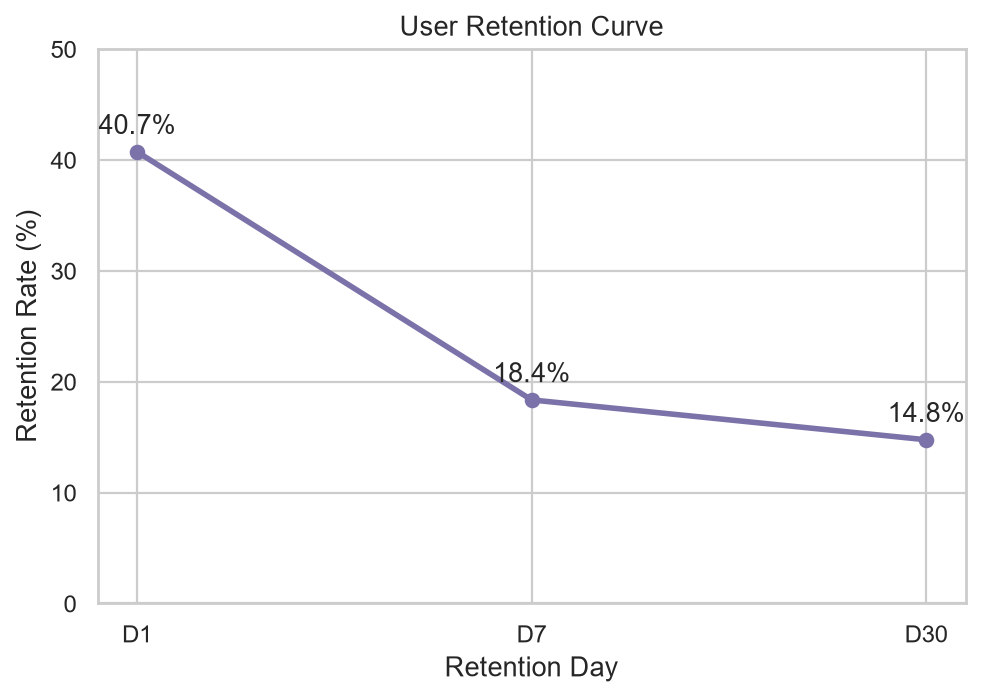

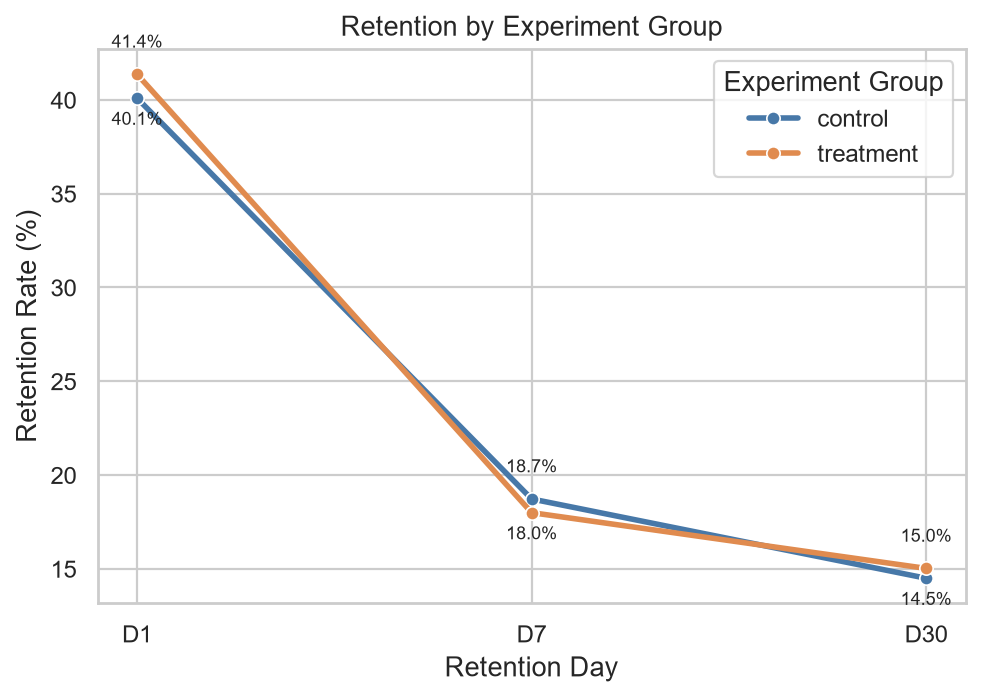

In [15]:
display(eda_results["retention"])
display(eda_results["retention_by_variant"])
display(Image(filename=str(project_root / "outputs" / "eda" / "retention_curve.png")))
display(Image(filename=str(project_root / "outputs" / "eda" / "retention_by_variant.png")))

,Metric,Control_Rate,Treatment_Rate,Difference_pp
0,Onboarding,53.197111,56.542783,3.345672
1,Trial,15.659679,17.095938,1.436258
2,Paid,10.146204,9.455488,-0.690716
3,D1 Retention,40.091598,41.365601,1.274003
4,D7 Retention,18.724679,17.994814,-0.729864
5,D30 Retention,14.497094,15.021608,0.524514


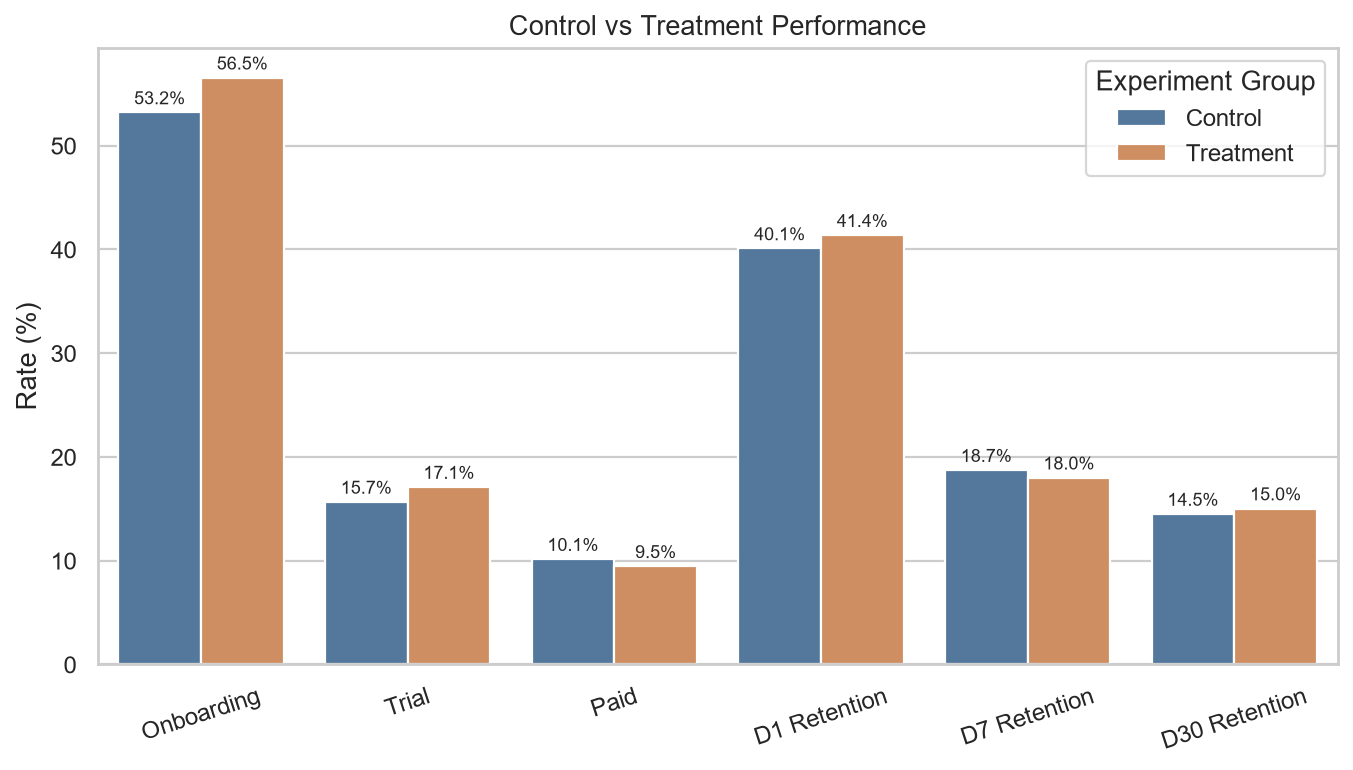

In [16]:
display(eda_results["comparison"])
display(Image(filename=str(project_root / "outputs" / "eda" / "control_treatment_comparison.png")))

Monthly assignment counts cover 3 months (2025-04-15 to 2025-06-30). April is a partial month because observations begin on April 15. This is an assignment trend, not a cohort analysis.


,Month,Assigned_Users
0,2025-04,940
1,2025-05,4871
2,2025-06,5651


,Field,Count,Mean,Median,Minimum,Maximum
0,Assignment minus signup delay (minutes),11462,1.01157,0.533333,0.133333,45.0


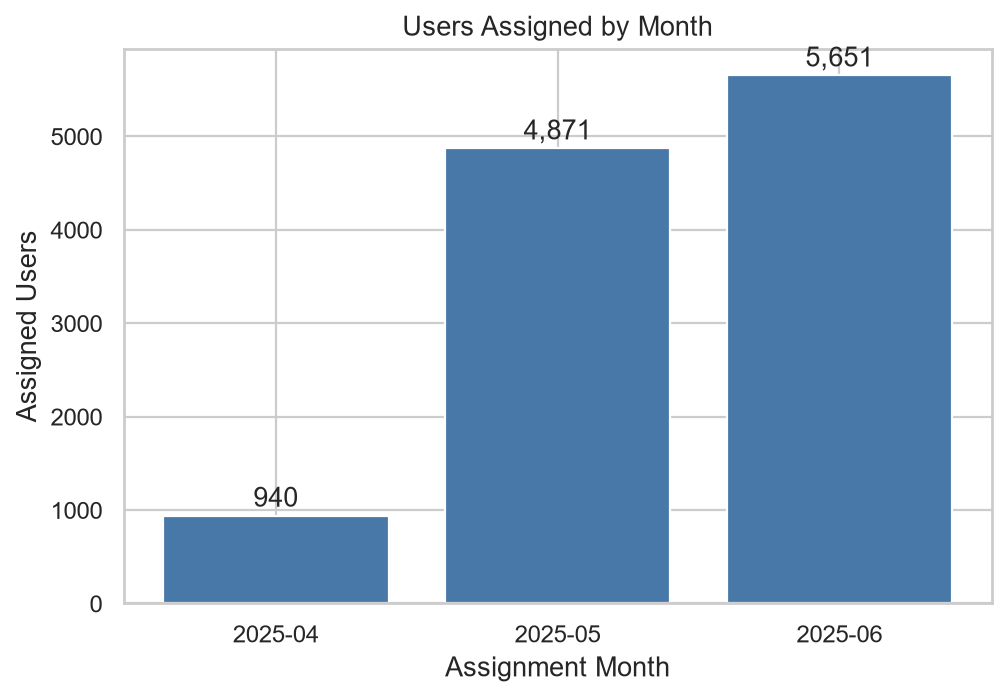


Key observations:
- The largest absolute funnel drop-off is Assigned -> Onboarding (5,171 users).
- The weakest funnel conversion is Trial Started at 29.79%.
- Paid conversion from all assigned users is 9.54% (1,093 of 11,462 users in the ordered funnel).
- Retention changes from 40.73% on D1 to 14.76% on D30, a decline of 25.97 percentage points; the largest adjacent drop is D1 to D7 (22.38 percentage points).
- Treatment has the higher onboarding rate by 3.35 percentage points; Control has the higher eligible paid-conversion rate by 0.69 points; and Treatment has the higher D30 retention rate by 0.52 points. In the ordered funnel, Control has the higher trial-to-paid rate by 10.33 points. These are descriptive differences, not significance tests.
- Among observed funnel flags, 32 records have a later-stage outcome without the preceding funnel stage; the ordered funnel excludes these records from downstream stages.


In [17]:
print(eda_results["time_note"])
if eda_results["time_trend"] is not None:
    display(eda_results["time_trend"][0])
    display(eda_results["time_trend"][1])
    display(Image(filename=str(project_root / "outputs" / "eda" / "time_trend.png")))
print("\nKey observations:")
for insight in eda_results["insights"]:
    print("-", insight)